In [1]:
#Section 9: Mini Data Analysis Project
#Exercise 24 — Sales Data Analysis
#Create Revenue = Units_Sold × Price. Analyze total units, total revenue, average revenue, highest-selling product, highest-revenue product, revenue by region/product, average units by region, and sorted revenue. 
#Create four requested visualizations and write 3–5 observations.

Total Units Sold: 170
Total Revenue: KSh 8,700,000
Average Revenue per Sale: KSh 870,000.0
Highest-Selling Product (Units): Phone
Highest-Revenue Product (Value): Phone


C:\Users\Wachira\AppData\Local\Temp\ipykernel_456\1158453135.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=prod_rev.index, y=prod_rev.values, ax=axes[0, 0], palette="Blues_r")
C:\Users\Wachira\AppData\Local\Temp\ipykernel_456\1158453135.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=reg_units.index, y=reg_units.values, ax=axes[0, 1], palette="Oranges")


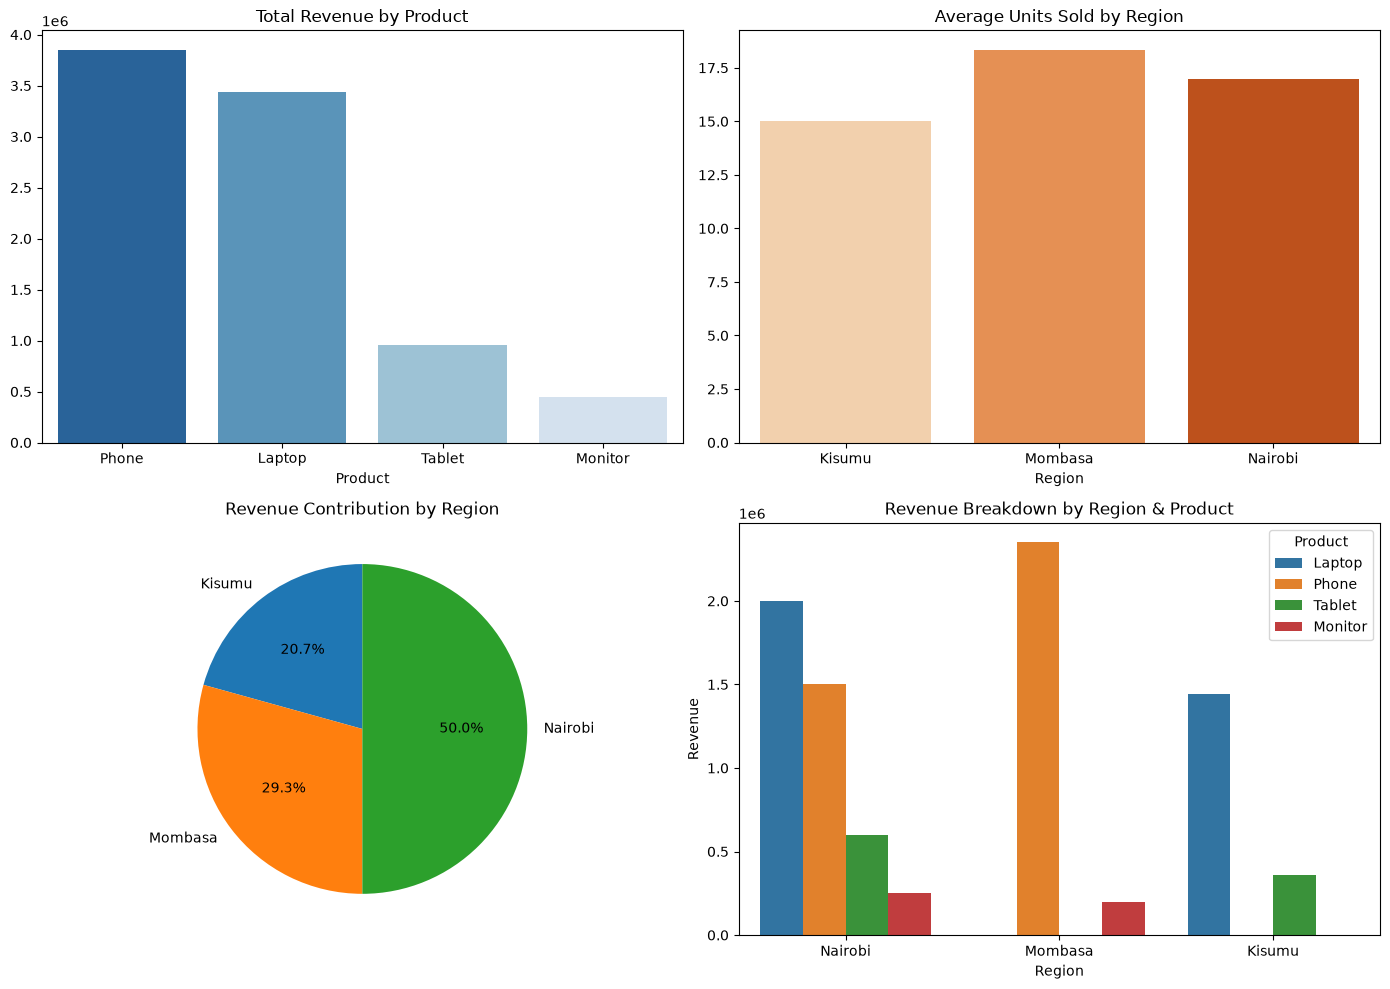

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

data = {
    "Product": ["Laptop", "Phone", "Laptop", "Tablet", "Phone", "Monitor", "Tablet", "Laptop", "Phone", "Monitor"],
    "Region": ["Nairobi", "Mombasa", "Nairobi", "Kisumu", "Nairobi", "Mombasa", "Nairobi", "Kisumu", "Mombasa", "Nairobi"],
    "Units_Sold": [10, 25, 15, 12, 30, 8, 20, 18, 22, 10],
    "Price": [80000, 50000, 80000, 30000, 50000, 25000, 30000, 80000, 50000, 25000]
}
df = pd.DataFrame(data)

# Your code here

df = pd.DataFrame(data)

# 1. Create Revenue column
df["Revenue"] = df["Units_Sold"] * df["Price"]

# 2. Comprehensive Metric Analysis
total_units = df["Units_Sold"].sum()
total_revenue = df["Revenue"].sum()
avg_revenue = df["Revenue"].mean()

# Grouped metrics
product_summary = (
    df.groupby("Product").agg({"Units_Sold": "sum", "Revenue": "sum"}).reset_index()
)
region_summary = (
    df.groupby("Region").agg({"Units_Sold": "mean", "Revenue": "sum"}).reset_index()
)
region_product_revenue = (
    df.groupby(["Region", "Product"])["Revenue"].sum().reset_index()
)

highest_selling_product = product_summary.loc[
    product_summary["Units_Sold"].idxmax(), "Product"
]
highest_revenue_product = product_summary.loc[
    product_summary["Revenue"].idxmax(), "Product"
]
sorted_df_revenue = df.sort_values(by="Revenue", ascending=False)

# Display Summary Results
print(f"Total Units Sold: {total_units}")
print(f"Total Revenue: KSh {total_revenue:,}")
print(f"Average Revenue per Sale: KSh {avg_revenue:,}")
print(f"Highest-Selling Product (Units): {highest_selling_product}")
print(f"Highest-Revenue Product (Value): {highest_revenue_product}")

# Code template to generate the 4 required plots:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Total Revenue by Product
prod_rev = df.groupby("Product")["Revenue"].sum().sort_values(ascending=False)
sns.barplot(x=prod_rev.index, y=prod_rev.values, ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("Total Revenue by Product")

# Plot 2: Average Units Sold by Region
reg_units = df.groupby("Region")["Units_Sold"].mean()
sns.barplot(x=reg_units.index, y=reg_units.values, ax=axes[0, 1], palette="Oranges")
axes[0, 1].set_title("Average Units Sold by Region")

# Plot 3: Revenue Share by Region
reg_rev = df.groupby("Region")["Revenue"].sum()
axes[1, 0].pie(reg_rev, labels=reg_rev.index, autopct="%1.1f%%", startangle=90)
axes[1, 0].set_title("Revenue Contribution by Region")

# Plot 4: Revenue by Region and Product
sns.barplot(
    data=df, x="Region", y="Revenue", hue="Product", ax=axes[1, 1],
    estimator="sum", errorbar=None
)
axes[1, 1].set_title("Revenue Breakdown by Region & Product")

plt.tight_layout()
plt.show()